# PPG power check

Measure power scores before choosing a cutoff. A low or high score alone does not prove signal quality.

In [2]:
from pathlib import Path
import json
import sys
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path('../src').resolve()))
from ppg_quality import inband_power_ratio

FS = 125
WINDOW = FS * 5
files = [Path('../data') / f'Part_{i}.mat' for i in range(1, 5)]
results = Path('../results')
graphs = results / 'graphs'
graphs.mkdir(parents=True, exist_ok=True)

## Measure each window

Use the raw PPG so filtering has not changed the score. Save the file, recording, starting row, and percentage for every full window.

In [3]:
rows = []
for path in files:
    with h5py.File(path, 'r') as f:
        for index, ref in enumerate(f[path.stem][:, 0]):
            data = f[ref]
            ppg = data[:, 0] if data.shape[1] == 3 else data[0, :]
            count = len(ppg) // WINDOW
            windows = ppg[:count * WINDOW].reshape(count, WINDOW)
            scores = inband_power_ratio(windows, fs=FS)
            rows.extend((path.name, index, w * WINDOW, float(score) * 100)
                        for w, score in enumerate(scores))
    print(f'Checked {path.name}', flush=True)

scores = pd.DataFrame(rows, columns=['file', 'record_index', 'start_sample', 'power_percent'])
del rows
scores.to_csv('../data/ppg_power_scores.csv', index=False)
print(f'Saved {len(scores):,} window scores')

Checked Part_1.mat


Checked Part_2.mat


Checked Part_3.mat


Checked Part_4.mat


Saved 528,828 window scores


## Look at the scores

Count how many scores fall below the old 60% rule. This is a comparison, not a rule for removing windows.

{
  "candidate_windows": 528828,
  "measurable_scores": 528828,
  "undefined_scores": 0,
  "below_60_percent": 1326,
  "below_60_share_percent": 0.2507431527831355,
  "percentiles": {
    "0": 24.28481465997944,
    "0.05": 83.69593094857971,
    "0.5": 97.29895235178182,
    "0.95": 99.599550550119,
    "1": 99.98464581425202
  },
  "cutoff_applied": null,
  "band_hz": [
    0.5,
    8
  ],
  "welch_segment_samples": 256,
  "window_samples": 625,
  "sampling_rate_hz": 125
}


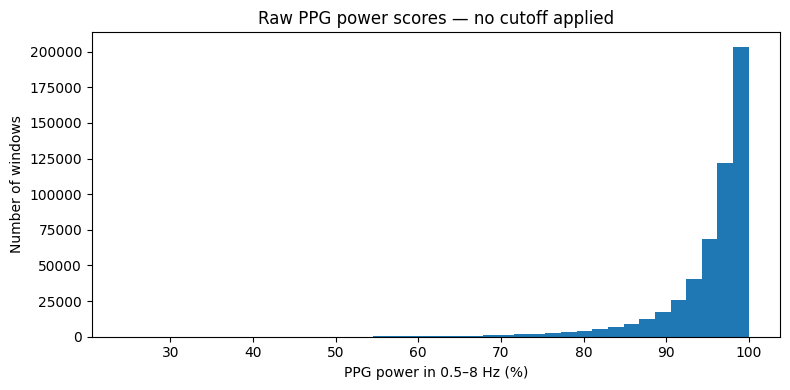

In [4]:
valid = scores['power_percent'].dropna()
summary = {
    'candidate_windows': len(scores),
    'measurable_scores': len(valid),
    'undefined_scores': int(scores['power_percent'].isna().sum()),
    'below_60_percent': int((valid < 60).sum()),
    'below_60_share_percent': float((valid < 60).mean() * 100),
    'percentiles': {str(q): float(valid.quantile(q)) for q in [0, 0.05, 0.5, 0.95, 1]},
    'cutoff_applied': None,
    'band_hz': [0.5, 8],
    'welch_segment_samples': 256,
    'window_samples': WINDOW,
    'sampling_rate_hz': FS,
}
(results / 'ppg_power_summary.json').write_text(json.dumps(summary, indent=2) + '\n')
print(json.dumps(summary, indent=2))

plt.figure(figsize=(8, 4))
plt.hist(valid, bins=40)
plt.xlabel('PPG power in 0.5–8 Hz (%)')
plt.ylabel('Number of windows')
plt.title('Raw PPG power scores — no cutoff applied')
plt.tight_layout()
plt.savefig(graphs / 'ppg_power_distribution.png', dpi=140)
plt.show()

## Inspect examples

Show three low scores and three high scores from different recordings. These are examples selected by score, not independently labeled good or bad signals.

      file  record_index  start_sample  power_percent group
Part_4.mat          1905         34375         24.285   low
Part_3.mat          2595         33750         26.341   low
Part_1.mat          1491           625         26.514   low
Part_2.mat           363          1875         99.985  high
Part_4.mat           563         40000         99.985  high
Part_2.mat          1013         22500         99.977  high


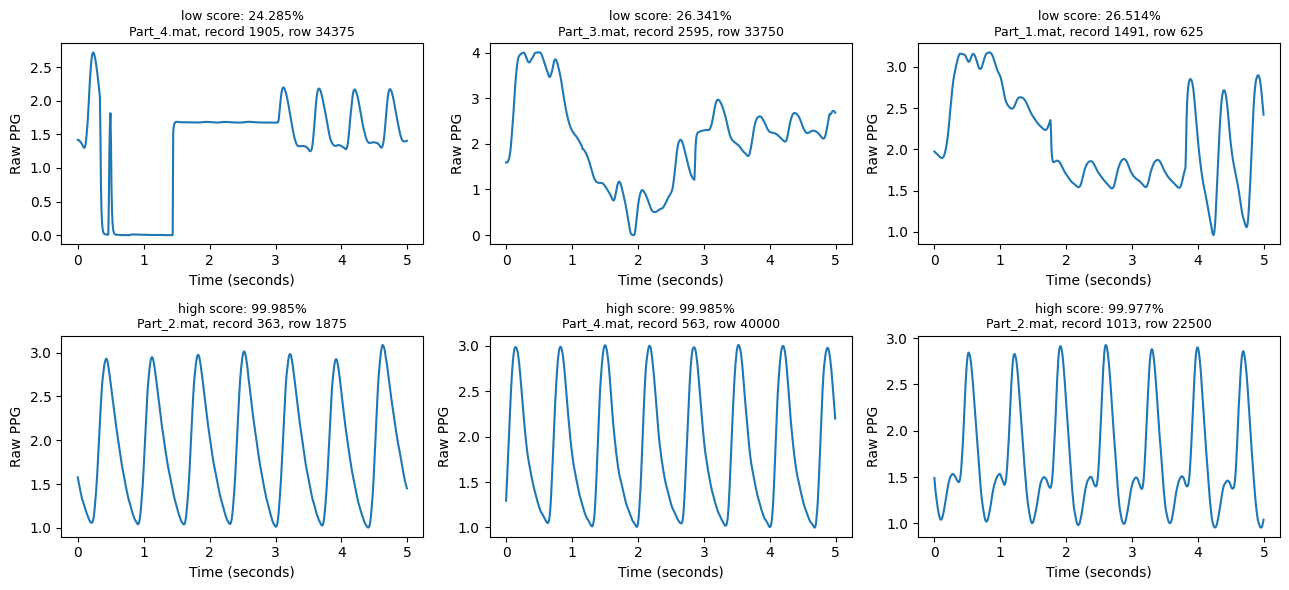

In [5]:
ordered = scores.dropna().sort_values('power_percent')
low = ordered.drop_duplicates(['file', 'record_index']).head(3)
high = ordered.iloc[::-1].drop_duplicates(['file', 'record_index']).head(3)
examples = pd.concat([low.assign(group='low'), high.assign(group='high')])
examples.to_csv(results / 'ppg_power_examples.csv', index=False)
print(examples.round(3).to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    path = Path('../data') / row['file']
    start = int(row['start_sample'])
    with h5py.File(path, 'r') as f:
        data = f[f[path.stem][int(row['record_index']), 0]]
        ppg = data[start:start + WINDOW, 0] if data.shape[1] == 3 else data[0, start:start + WINDOW]
    ax.plot(np.arange(WINDOW) / FS, ppg)
    ax.set_title(f"{row['group']} score: {row['power_percent']:.3f}%\n{row['file']}, record {row['record_index']}, row {start}", fontsize=9)
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Raw PPG')
plt.tight_layout()
plt.savefig(graphs / 'ppg_power_examples.png', dpi=140)
plt.show()